<a href="https://colab.research.google.com/github/YeweonJung/workshop/blob/main/%ED%9A%A8%EA%B3%BC%EC%A7%80%ED%91%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 효과지표 실습

## 1. RR · OR · RRR · ARR · NNT
각 군 1,000명: 대조군 200명, 치료군 100명에서 사건 발생.

,0
Control risk,0.200000
Treatment risk,0.100000
RR,0.500000
OR,0.444444
RRR (%),50.000000
ARR (%p),10.000000
NNT (2 years),10.000000


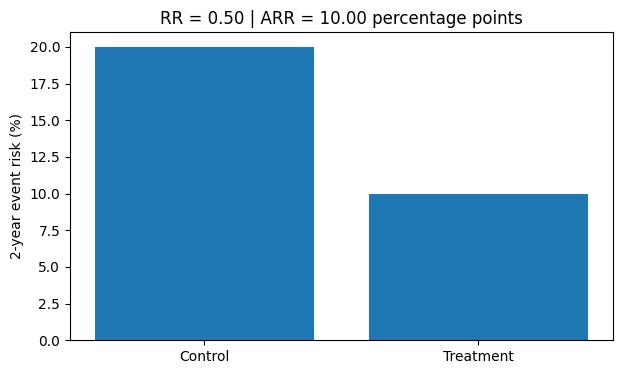

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.stats.contingency_tables import Table2x2
from statsmodels.stats.proportion import confint_proportions_2indep
import statsmodels.api as sm

plt.rcParams['figure.figsize'] = (7, 4)

n_c, n_t = 1000, 1000  # 군별 인원
e_c, e_t = 200, 100    # 사건 수: 이 숫자를 바꿔보세요
assert 0 < e_c < n_c and 0 < e_t < n_t
p_c, p_t = e_c / n_c, e_t / n_t
rr = p_t / p_c
odds_c, odds_t = p_c / (1 - p_c), p_t / (1 - p_t)
or_ = odds_t / odds_c
arr = p_c - p_t
nnt = np.ceil(1 / arr) if arr > 0 else np.nan
display(pd.Series({'Control risk': p_c, 'Treatment risk': p_t,
                   'RR': rr, 'OR': or_, 'RRR (%)': 100 * (1 - rr),
                   'ARR (%p)': 100 * arr, 'NNT (2 years)': nnt}))
plt.bar(['Control', 'Treatment'], [100 * p_c, 100 * p_t])
plt.ylabel('2-year event risk (%)')
plt.title(f'RR = {rr:.2f} | ARR = {100 * arr:.2f} percentage points')
plt.show()

## 2. 같은 RR, 다른 ARR · NNT

,Control (%),Treatment (%),RR,RRR (%),ARR (%p),NNT (2 years)
A: high baseline risk,20.0,10.0,0.5,50.0,10.0,10
B: low baseline risk,0.2,0.1,0.5,50.0,0.1,1000


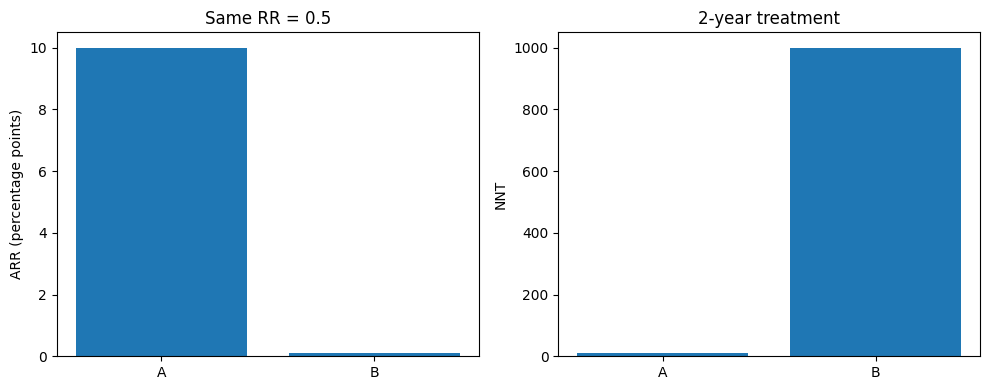

In [ ]:
p_c = np.array([0.20, 0.002])
p_t = p_c * 0.5
result = pd.DataFrame({'Control (%)': p_c * 100, 'Treatment (%)': p_t * 100,
                       'RR': p_t / p_c, 'RRR (%)': (1 - p_t / p_c) * 100,
                       'ARR (%p)': (p_c - p_t) * 100,
                       'NNT (2 years)': np.ceil(1 / (p_c - p_t)).astype(int)},
                      index=['A: high baseline risk', 'B: low baseline risk'])
display(result)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(['A', 'B'], result['ARR (%p)'])
axes[0].set(ylabel='ARR (percentage points)', title='Same RR = 0.5')
axes[1].bar(['A', 'B'], result['NNT (2 years)'])
axes[1].set(ylabel='NNT', title='2-year treatment')
plt.tight_layout()
plt.show()

## 3. OR은 RR과 얼마나 다른가?

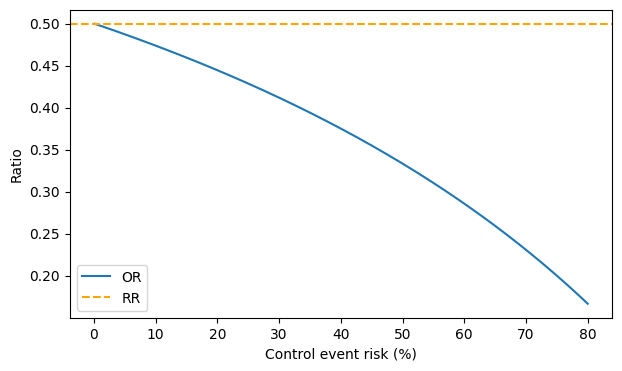

In [ ]:
p_c = np.linspace(0.001, 0.8, 200)
rr = 0.5  # 바꿔보세요. p_c * rr은 1 미만이어야 합니다.
p_t = p_c * rr
assert np.all(p_t < 1)
or_ = (p_t / (1 - p_t)) / (p_c / (1 - p_c))
plt.plot(p_c * 100, or_, label='OR')
plt.axhline(rr, color='orange', linestyle='--', label='RR')
plt.xlabel('Control event risk (%)')
plt.ylabel('Ratio')
plt.legend()
plt.show()

## 4. 부작용: ARI · NNH

,0
ARI (%p),3.0
NNH (2 years),34.0


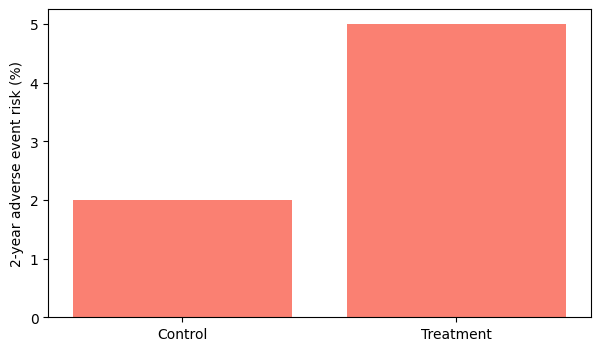

In [ ]:
harm_c, harm_t = 0.02, 0.05
ari = harm_t - harm_c
nnh = np.ceil(1 / ari) if ari > 0 else np.nan
display(pd.Series({'ARI (%p)': ari * 100, 'NNH (2 years)': nnh}))
plt.bar(['Control', 'Treatment'], [harm_c * 100, harm_t * 100], color='salmon')
plt.ylabel('2-year adverse event risk (%)')
plt.show()

## 5. 95% 신뢰구간

,Estimate,Lower 95%,Upper 95%
RR,0.5000,0.3999,0.6252
OR,0.4444,0.3433,0.5754
ARR (%p),10.0000,6.8949,13.1046


2-year NNT 95% CI: [ 8 15]


/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


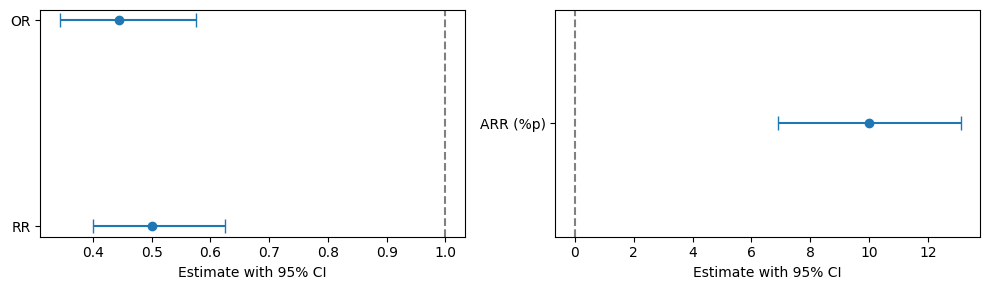

In [ ]:
table = Table2x2([[e_t, n_t - e_t], [e_c, n_c - e_c]])
arr = e_c / n_c - e_t / n_t
arr_ci = confint_proportions_2indep(e_c, n_c, e_t, n_t, method='newcomb')
ci = pd.DataFrame([
    [table.riskratio, *table.riskratio_confint()],
    [table.oddsratio, *table.oddsratio_confint()],
    [arr * 100, arr_ci[0] * 100, arr_ci[1] * 100]
], index=['RR', 'OR', 'ARR (%p)'], columns=['Estimate', 'Lower 95%', 'Upper 95%'])
display(ci.round(4))
if arr_ci[0] > 0:
    print('2-year NNT 95% CI:', np.ceil(1 / np.array(arr_ci)[::-1]).astype(int))
else:
    print('ARR CI가 0 이하에 걸치므로 단일 유한 NNT 구간으로 표시하지 않습니다.')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, names, null in [(axes[0], ['RR', 'OR'], 1), (axes[1], ['ARR (%p)'], 0)]:
    r = ci.loc[names]
    ax.errorbar(r['Estimate'], names,
                xerr=[r['Estimate'] - r['Lower 95%'], r['Upper 95%'] - r['Estimate']],
                fmt='o', capsize=5)
    ax.axvline(null, color='gray', linestyle='--')
    ax.set_xlabel('Estimate with 95% CI')
plt.tight_layout()
plt.show()

## 6. 표본 수와 통계적 유의성

,n per group,ARR (%p),Lower 95%,Upper 95%,CI excludes 0
0,1000,0.1,-0.386413,0.632684,False
1,10000,0.1,-0.009653,0.217937,False
2,100000,0.1,0.066319,0.134581,True


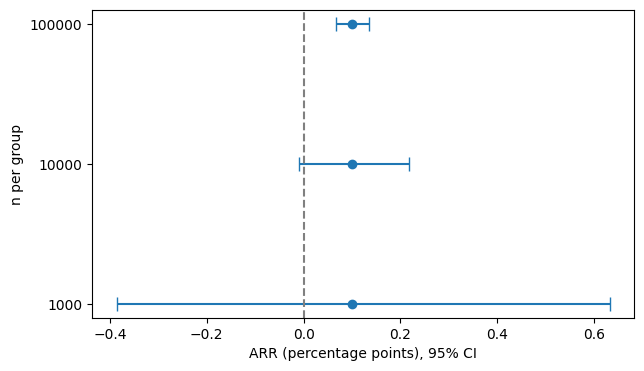

In [ ]:
rows = []
for n in [1000, 10000, 100000]:
    ec, et = int(n * 0.002), int(n * 0.001)
    lo, hi = confint_proportions_2indep(ec, n, et, n, method='newcomb')
    rows.append([n, 0.1, lo * 100, hi * 100, lo > 0])
size = pd.DataFrame(rows, columns=['n per group', 'ARR (%p)', 'Lower 95%', 'Upper 95%', 'CI excludes 0'])
display(size)
plt.errorbar(size['ARR (%p)'], size['n per group'].astype(str),
             xerr=[size['ARR (%p)'] - size['Lower 95%'], size['Upper 95%'] - size['ARR (%p)']],
             fmt='o', capsize=5)
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('ARR (percentage points), 95% CI')
plt.ylabel('n per group')
plt.show()

## 7. 개인별 자료 → 로지스틱 회귀 OR

In [ ]:
data = pd.DataFrame({
    'treatment': np.repeat([0, 1], [n_c, n_t]),
    'event': np.r_[np.ones(e_c), np.zeros(n_c-e_c), np.ones(e_t), np.zeros(n_t-e_t)]
})
model = sm.Logit(data['event'], sm.add_constant(data['treatment'])).fit(disp=False)
display(data.head())
print('Logistic OR:', np.exp(model.params['treatment']).round(4))
print('95% CI:', np.exp(model.conf_int().loc['treatment']).round(4).tolist())
print('2 x 2 OR:', round(table.oddsratio, 4))

,treatment,event
0,0,1.0
1,0,1.0
2,0,1.0
3,0,1.0
4,0,1.0


Logistic OR: 0.4444
95% CI: [0.3433, 0.5754]
2 x 2 OR: 0.4444


## 8. 사건 발생 시간 · 중도절단 · HR
군별 1,000명, 최대 5년 추적. HR=0.6인 비례위험과 독립적인 탈락을 가정

,treatment,time,event
0,0,5.000000,0
1,0,5.000000,0
2,0,1.528293,0
3,0,1.398971,1
4,0,0.432187,1
5,0,5.000000,0
6,0,5.000000,0
7,0,5.000000,0
8,0,0.396471,1
9,0,1.416692,0


Cox HR: 0.563
95% CI: [0.491 0.646]


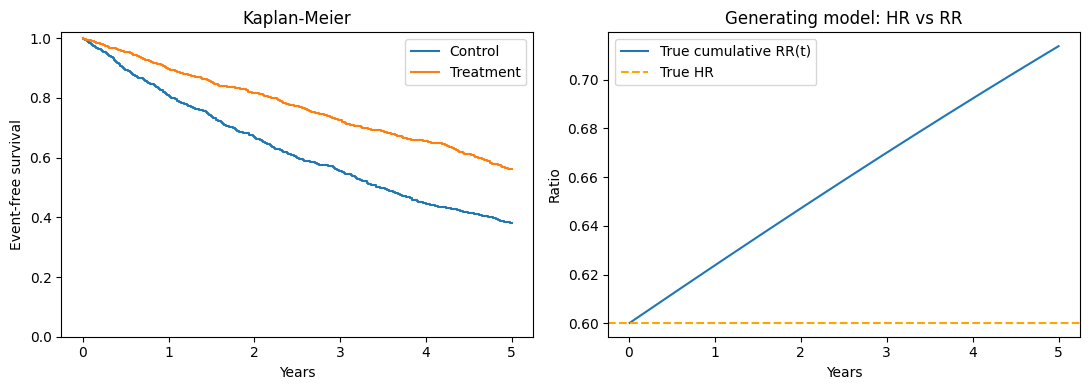

In [ ]:
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import SurvfuncRight

rng = np.random.default_rng(42)
treatment = np.repeat([0, 1], 1000)
true_hr = 0.6  # 바꿔보세요
rate = 0.20 * true_hr ** treatment
event_time = rng.exponential(1 / rate)
censor_time = np.minimum(rng.exponential(10, len(treatment)), 5)
survival = pd.DataFrame({'treatment': treatment,
                         'time': np.minimum(event_time, censor_time),
                         'event': (event_time <= censor_time).astype(int)})
display(survival.head(10))  # event=0: 관찰 종료까지 사건이 관측되지 않음
cox = PHReg(survival['time'], survival[['treatment']], status=survival['event']).fit()
print('Cox HR:', np.exp(cox.params[0]).round(3))
print('95% CI:', np.exp(cox.conf_int()[0]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for group, label in [(0, 'Control'), (1, 'Treatment')]:
    d = survival[survival.treatment == group]
    km = SurvfuncRight(d.time, d.event)
    axes[0].step(np.r_[0, km.surv_times, 5], np.r_[1, km.surv_prob, km.surv_prob[-1]],
                 where='post', label=label)
axes[0].set(xlabel='Years', ylabel='Event-free survival', ylim=(0, 1.02), title='Kaplan-Meier')
axes[0].legend()
years = np.linspace(0.01, 5, 200)
risk_c = 1 - np.exp(-0.20 * years)
risk_t = 1 - np.exp(-0.20 * true_hr * years)
axes[1].plot(years, risk_t / risk_c, label='True cumulative RR(t)')
axes[1].axhline(true_hr, linestyle='--', color='orange', label='True HR')
axes[1].set(xlabel='Years', ylabel='Ratio', title='Generating model: HR vs RR')
axes[1].legend()
plt.tight_layout()
plt.show()